Developing a model to predict individuals who would not default and who is likely to default

In [1]:
# importing libraries
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import category_encoders as ce

from sklearn import ensemble
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, mean_squared_error
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from pandas.core.dtypes.common import is_numeric_dtype
import catboost as cb

Load dataset

In [2]:
df = pd.read_csv("German_bank.csv")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   checking_balance      1000 non-null   object
 1   months_loan_duration  1000 non-null   int64 
 2   credit_history        1000 non-null   object
 3   purpose               1000 non-null   object
 4   amount                1000 non-null   int64 
 5   savings_balance       1000 non-null   object
 6   employment_duration   1000 non-null   object
 7   percent_of_income     1000 non-null   int64 
 8   years_at_residence    1000 non-null   int64 
 9   age                   1000 non-null   int64 
 10  other_credit          1000 non-null   object
 11  housing               1000 non-null   object
 12  existing_loans_count  1000 non-null   int64 
 13  job                   1000 non-null   object
 14  dependents            1000 non-null   int64 
 15  phone                 1000 non-null   o

Pre-process

In [3]:
# there are no nulls, checking there could be empty values
df_clean = df.replace('', np.nan)
nan_values = df_clean[df_clean.isna().any(axis=1)]
print(nan_values)

# checking cardinality
print(df_clean.apply(pd.Series.nunique))

# encode categorical features suitably. https://towardsdatascience.com/beyond-one-hot-17-ways-of-transforming-categorical-features-into-numeric-features-57f54f199ea4 and https://medium.com/@brandon93.w/converting-categorical-data-into-numerical-form-a-practical-guide-for-data-science-99fdf42d0e10 gave me the required background for the choice of encoders. 
ord_enc = OrdinalEncoder(categories=[['critical', 'poor', 'good', 'very good', 'perfect'], 
                                        ['unemployed', '< 1 year', '1 - 4 years', '4 - 7 years', '> 7 years'], 
                                     ['no', 'yes']])
df_clean[['credit_history', 'employment_duration', 'phone']] = ord_enc.fit_transform(df_clean[['credit_history', 'employment_duration', 'phone']])
df_clean['credit_history'] = df_clean['credit_history'].astype(int)
df_clean['employment_duration'] = df_clean['employment_duration'].astype(int)
df_clean['phone'] = df_clean['phone'].astype(int)
df_clean = ce.BinaryEncoder(cols=['checking_balance', 'purpose', 'savings_balance', 'other_credit', 'housing', 'job']).fit_transform(df_clean)
df_clean = pd.get_dummies(df_clean, columns=['default'], drop_first=True)
df_clean.info()
print(df_clean.apply(pd.Series.nunique))

Empty DataFrame
Columns: [checking_balance, months_loan_duration, credit_history, purpose, amount, savings_balance, employment_duration, percent_of_income, years_at_residence, age, other_credit, housing, existing_loans_count, job, dependents, phone, default]
Index: []
checking_balance          4
months_loan_duration     33
credit_history            5
purpose                   6
amount                  921
savings_balance           5
employment_duration       5
percent_of_income         4
years_at_residence        4
age                      53
other_credit              3
housing                   3
existing_loans_count      4
job                       4
dependents                2
phone                     2
default                   2
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   checking_balance_0    1000 non-nu

Check correlation

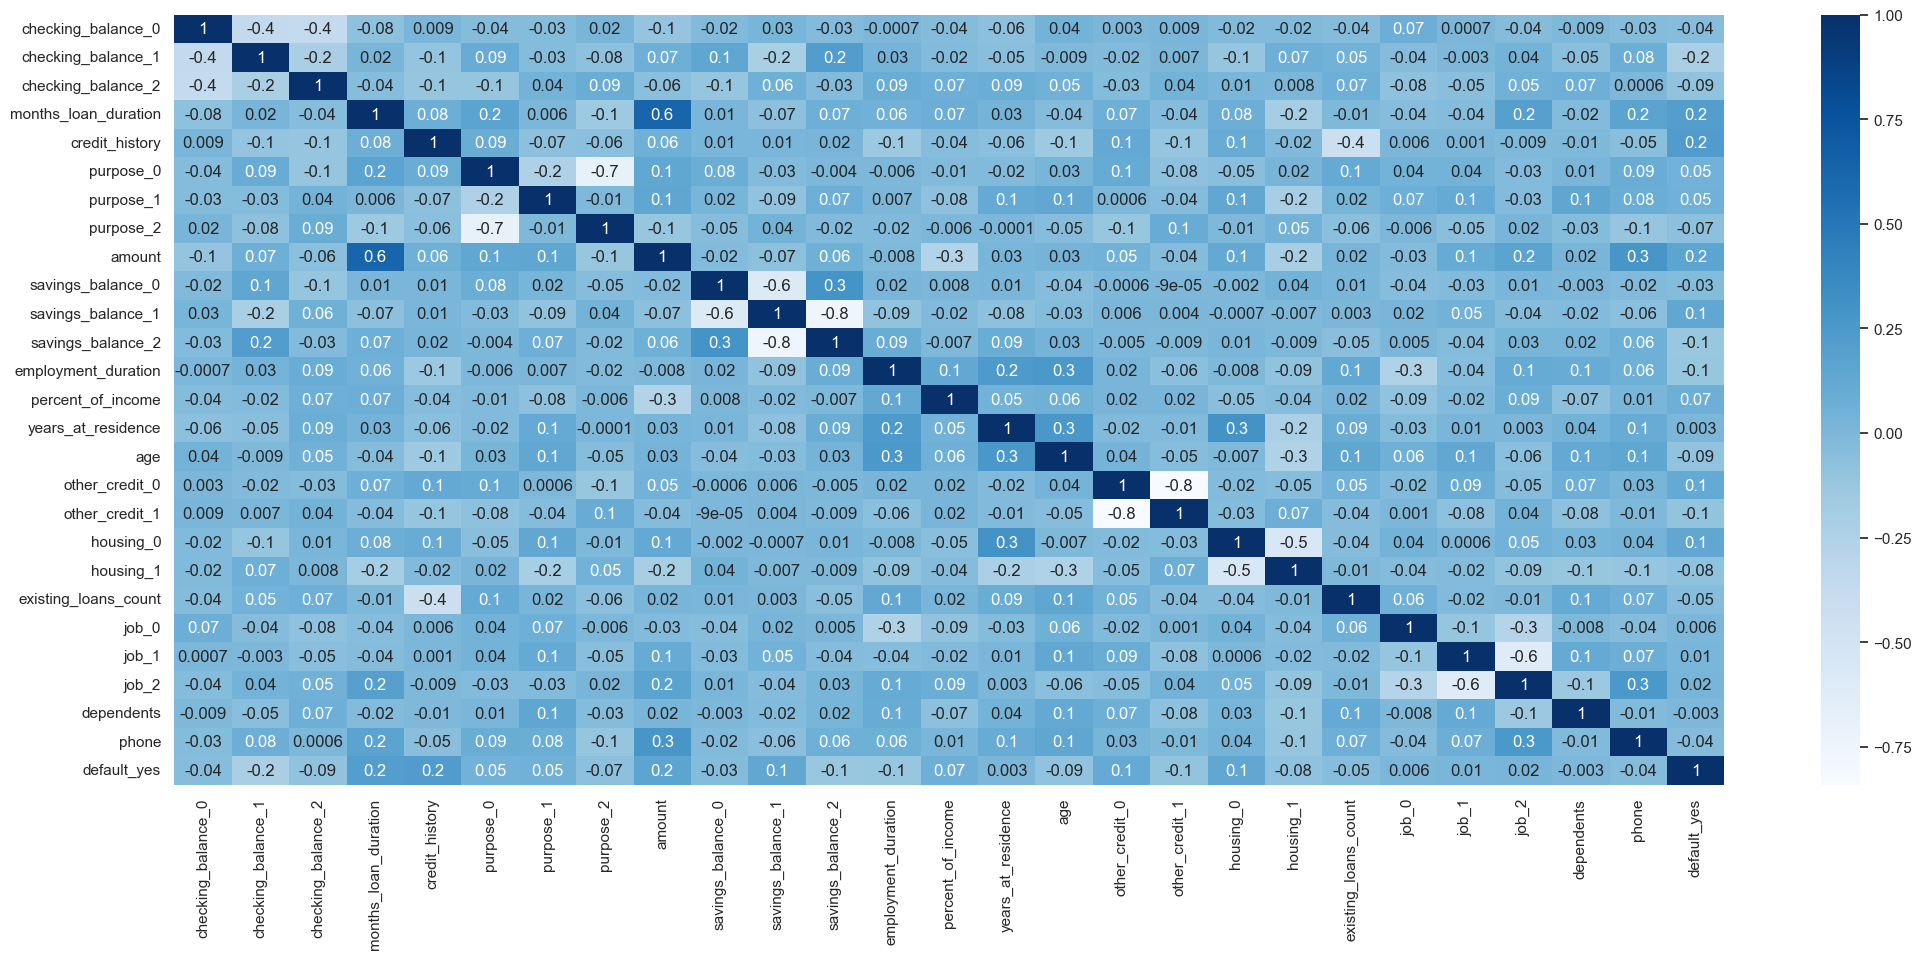

In [4]:
plt.figure(figsize=(25,10))
sns.set_theme(style="dark")
corr = df_clean.corr()
heatmap = sns.heatmap(corr, annot=True, cmap="Blues", fmt='.1g')

Purpose, age, dependents and phone seem to have low correlation. We can perhaps try dropping those in a future experiment.

Create training and test sets

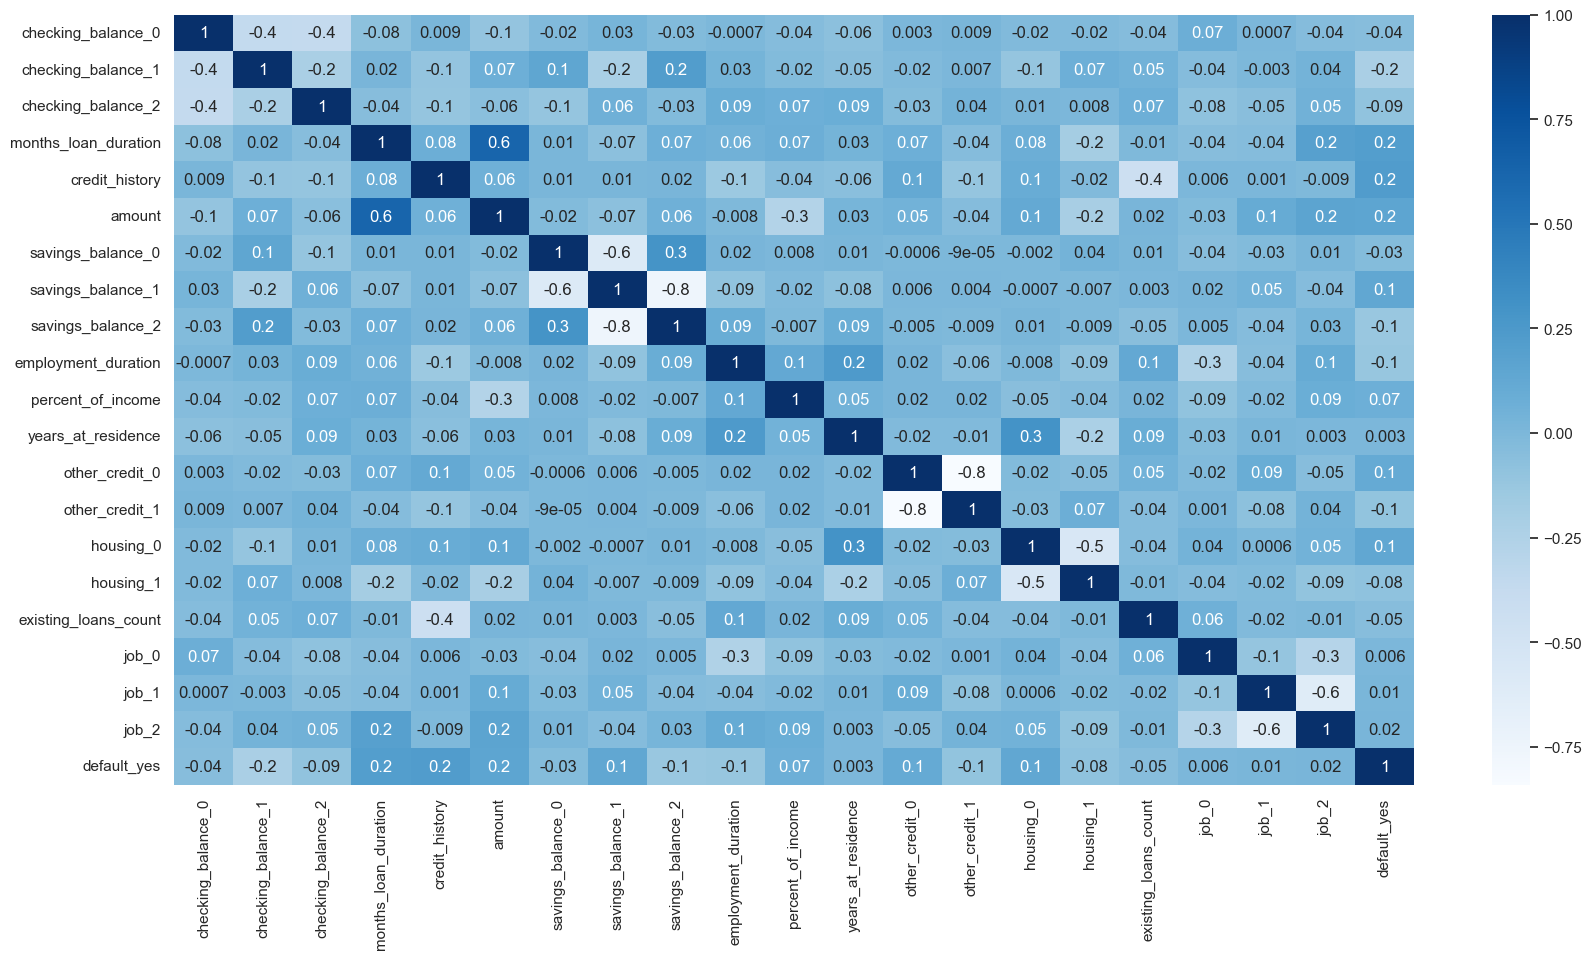

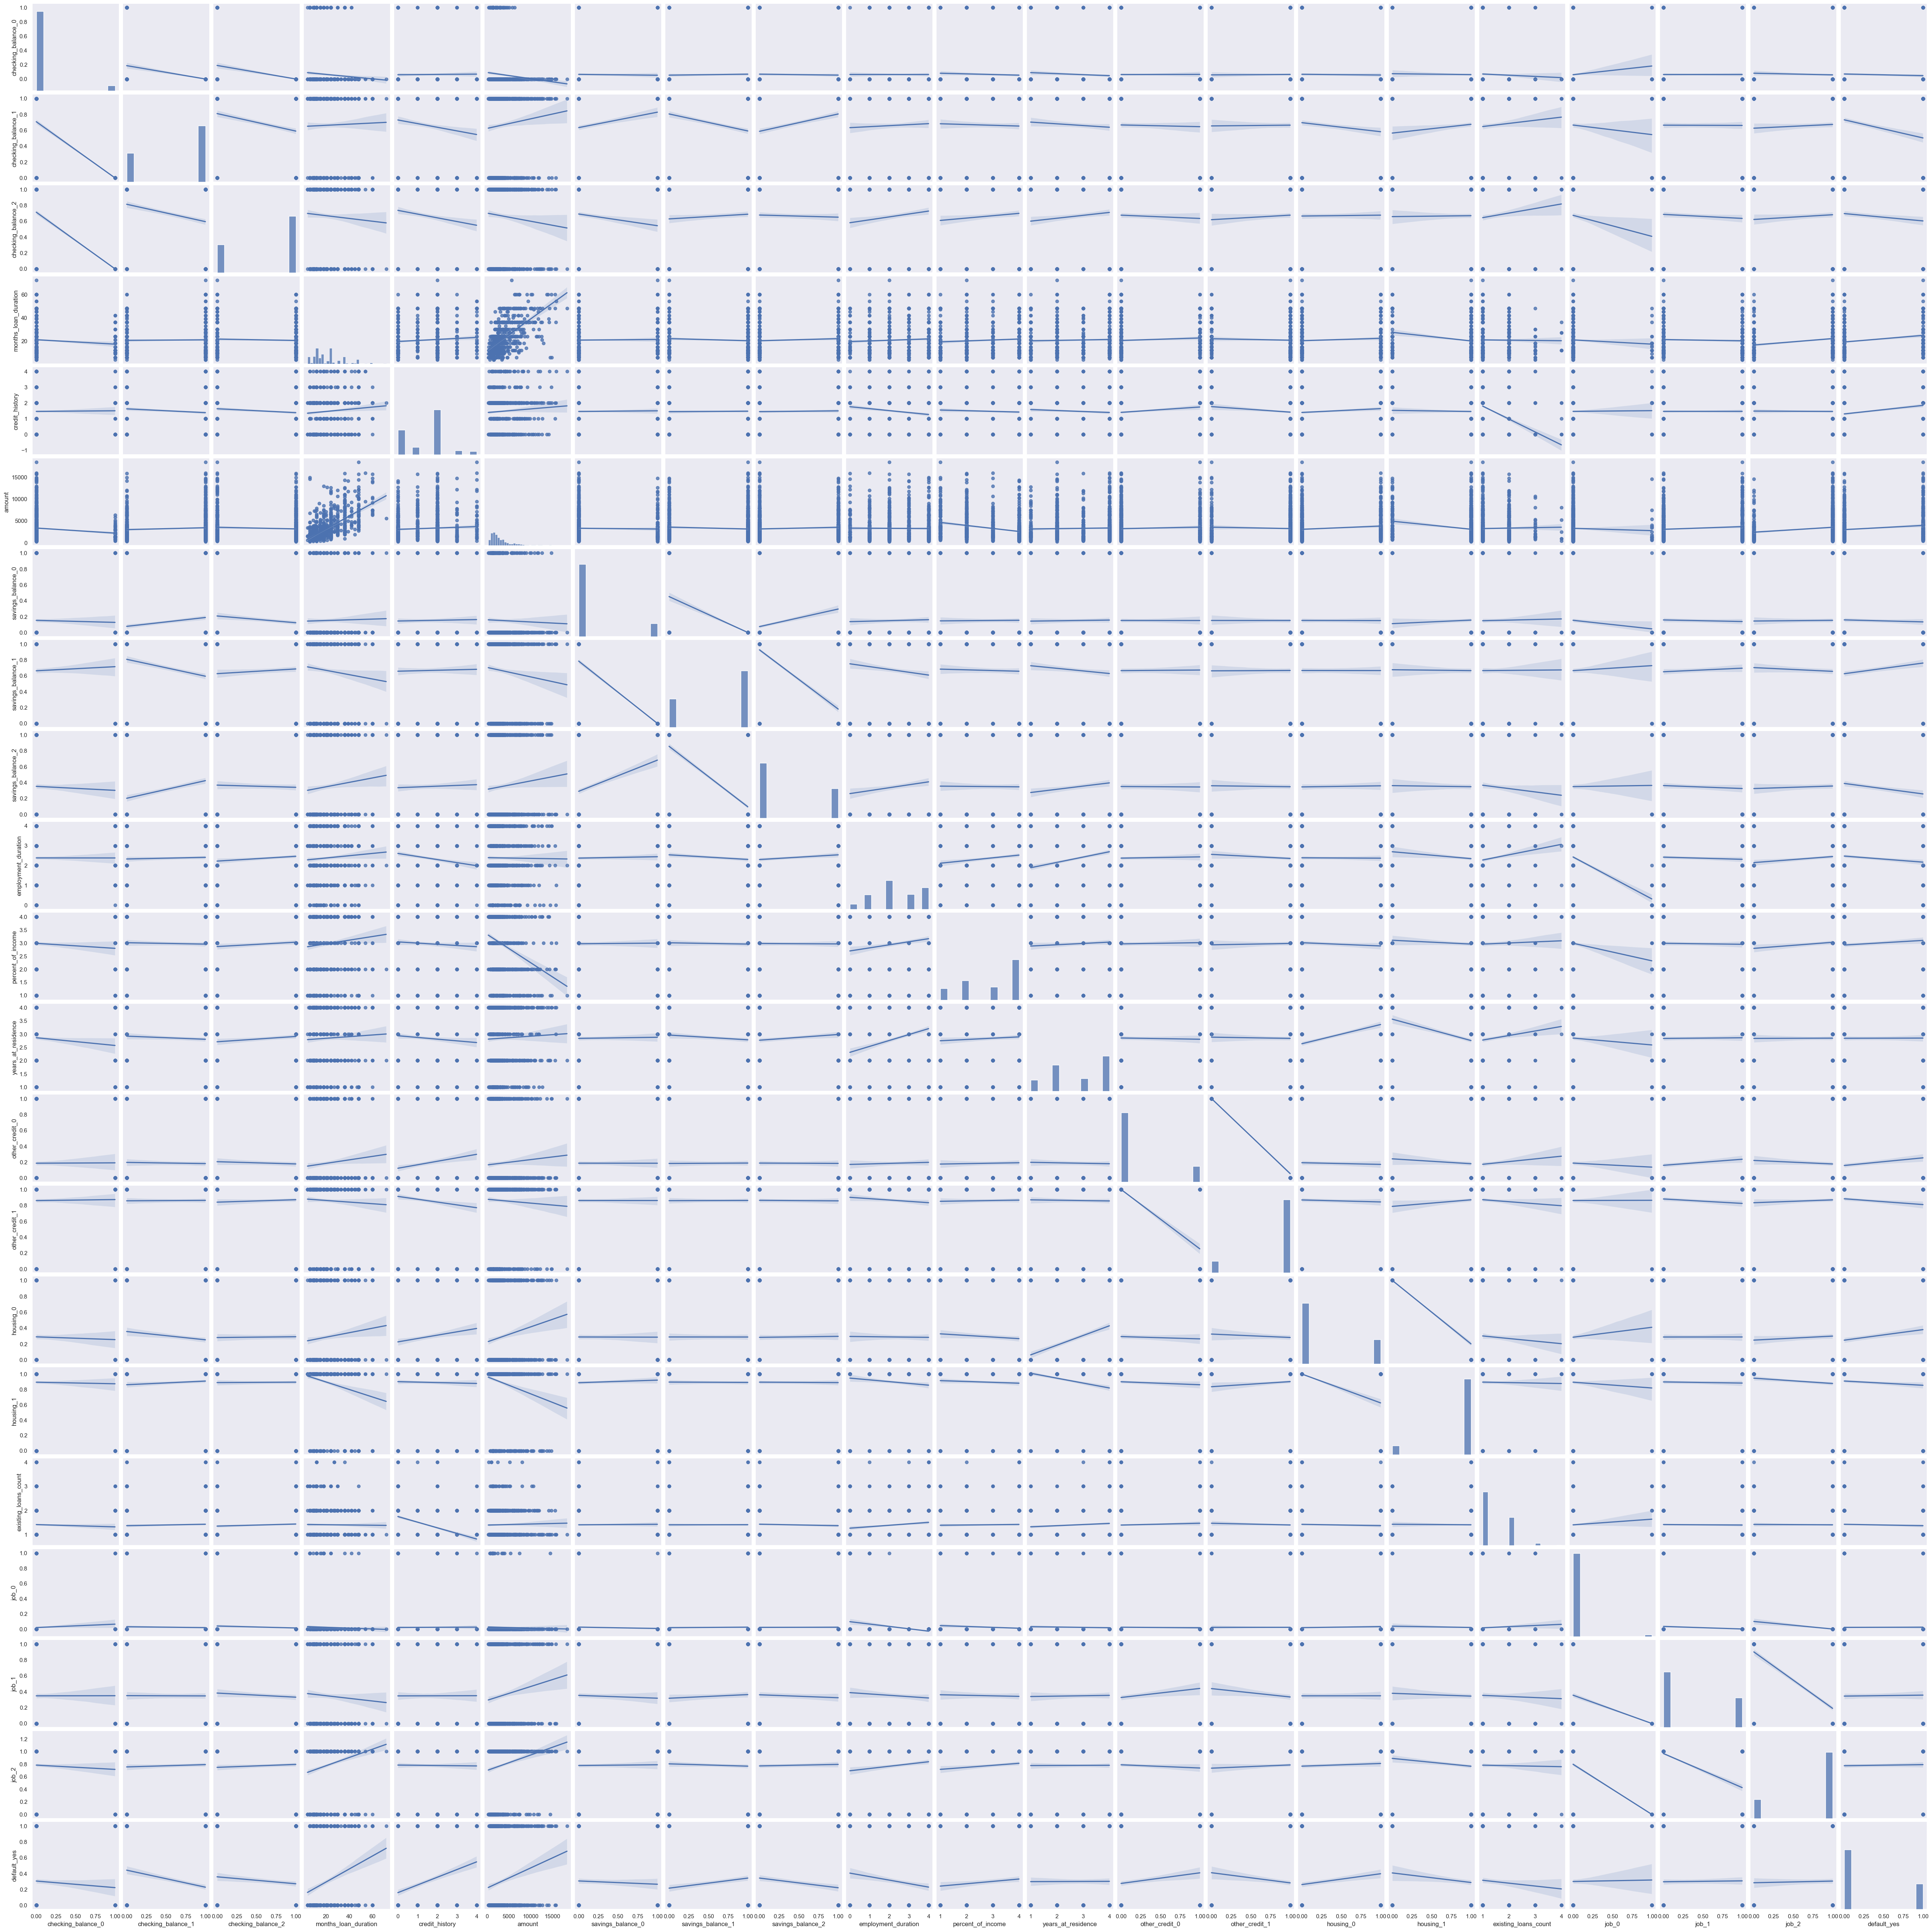

In [5]:
df_clean= df_clean.drop(columns=['purpose_0', 'purpose_1', 'purpose_2', 'age', 'dependents', 'phone'])
plt.figure(figsize=(20,10))
corr = df_clean.corr()
heatmap = sns.heatmap(corr, annot=True, cmap="Blues", fmt='.1g')
sns.pairplot(df_clean, kind="reg")

In [6]:
X = df_clean.iloc[:,:-1]
y = df_clean['default_yes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1984, stratify=y)
y.head()

0    False
1     True
2    False
3    False
4     True
Name: default_yes, dtype: bool

Benchmark with Logit
It is a binary classification problem with a continuous likelihood probability.

In [7]:
logreg = sm.Logit(y_train, sm.add_constant(X_train)).fit()
print(logreg.summary())
y_hat = logreg.predict(sm.add_constant(X_test))
prediction = list(map(round, y_hat))

# comparing original and predicted values of y 
print('Actual values', list(y_test.values))
print('Predictions :', prediction)

# confusion matrix
cm = confusion_matrix(y_test, prediction)
print ("Confusion Matrix : \n", cm)

# accuracy score of the model 
print('Test accuracy = ', accuracy_score(y_test, prediction))

Optimization terminated successfully.
         Current function value: 0.483516
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            default_yes   No. Observations:                  800
Model:                          Logit   Df Residuals:                      779
Method:                           MLE   Df Model:                           20
Date:                Mon, 04 Dec 2023   Pseudo R-squ.:                  0.2085
Time:                        00:16:19   Log-Likelihood:                -386.81
converged:                       True   LL-Null:                       -488.69
Covariance Type:            nonrobust   LLR p-value:                 2.030e-32
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -1.8551      0.993     -1.868      0.062      -3.801       0.091

Observation:
The accuracy of 0.755 (0.76 with the dropped features) is not good enough. The recall of 33 out of 54 is not too bad for a loan default prediction system, however, the low precision of 33 out of 60 could hurt genuine loan seekers.

Try LDA

              precision    recall  f1-score   support

       False       0.80      0.89      0.84       560
        True       0.64      0.47      0.54       240

    accuracy                           0.76       800
   macro avg       0.72      0.68      0.69       800
weighted avg       0.75      0.76      0.75       800


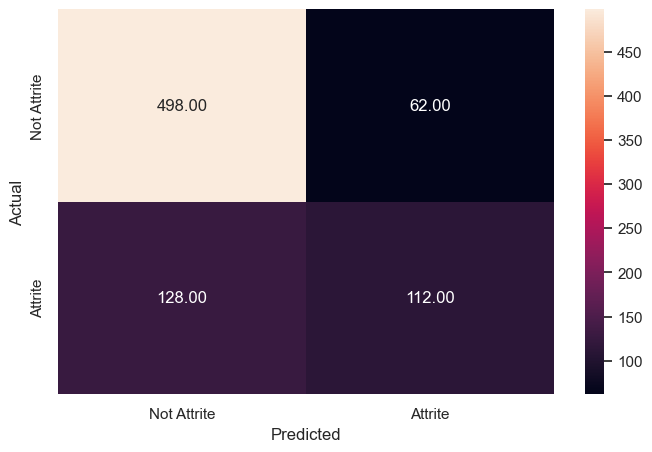

In [8]:
def metrics_score(actual, predicted):
    # borrowed from mentor session
    print(classification_report(actual, predicted))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize = (8, 5))
    sns.heatmap(cm, annot = True, fmt = '.2f', xticklabels = ['Not Attribute', 'Attribute'], yticklabels = ['Not Attribute', 'Attribute'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred_train_lda = lda.predict(X_train)
metrics_score(y_train, y_pred_train_lda)

              precision    recall  f1-score   support

       False       0.82      0.84      0.83       140
        True       0.60      0.57      0.58        60

    accuracy                           0.76       200
   macro avg       0.71      0.70      0.70       200
weighted avg       0.75      0.76      0.75       200


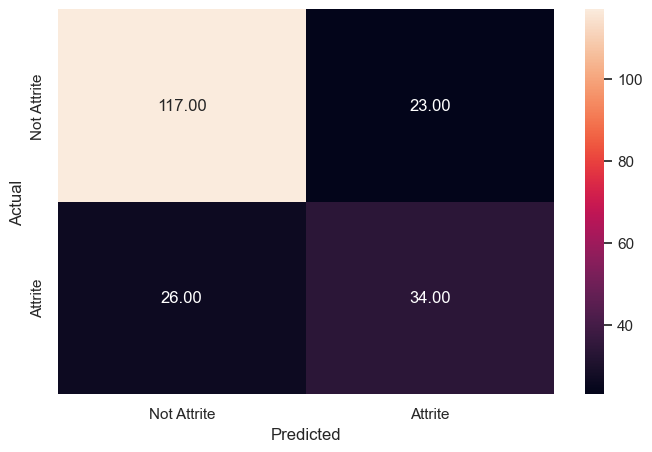

In [9]:
y_pred_test_lda = lda.predict(X_test)
metrics_score(y_test, y_pred_test_lda)

Performance only marginally better.

Try QDA

              precision    recall  f1-score   support

       False       0.80      0.89      0.84       560
        True       0.64      0.47      0.54       240

    accuracy                           0.76       800
   macro avg       0.72      0.68      0.69       800
weighted avg       0.75      0.76      0.75       800


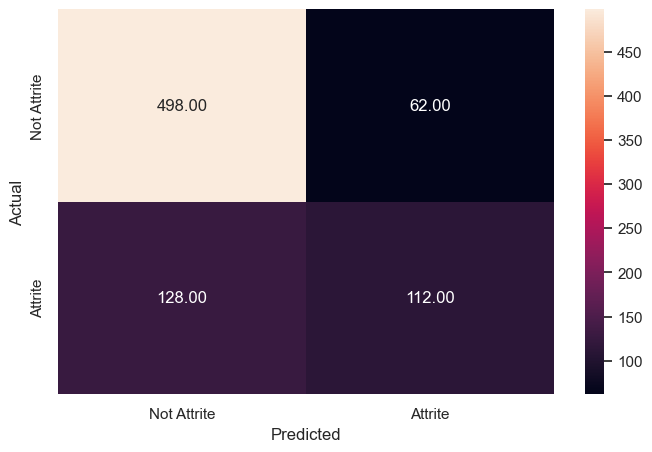

In [10]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)
y_pred_train_qda = qda.predict(X_train)
metrics_score(y_train, y_pred_train_lda)

              precision    recall  f1-score   support

       False       0.83      0.79      0.81       140
        True       0.56      0.62      0.59        60

    accuracy                           0.74       200
   macro avg       0.69      0.70      0.70       200
weighted avg       0.75      0.74      0.74       200


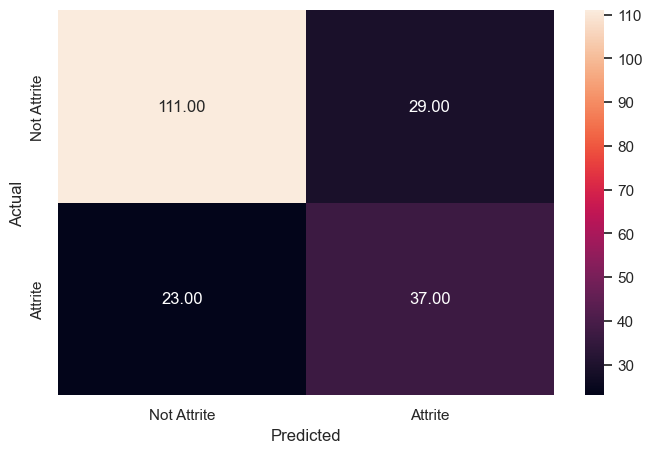

In [11]:
y_pred_test_qda = qda.predict(X_test)
metrics_score(y_test, y_pred_test_qda)

Performance is poorer. Perhaps overfitting with low correlation features.

Trying KNN

In [12]:
knn = KNeighborsClassifier(n_neighbors = 6)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=6)

              precision    recall  f1-score   support

       False       0.73      0.97      0.83       560
        True       0.70      0.15      0.24       240

    accuracy                           0.73       800
   macro avg       0.71      0.56      0.54       800
weighted avg       0.72      0.72      0.65       800


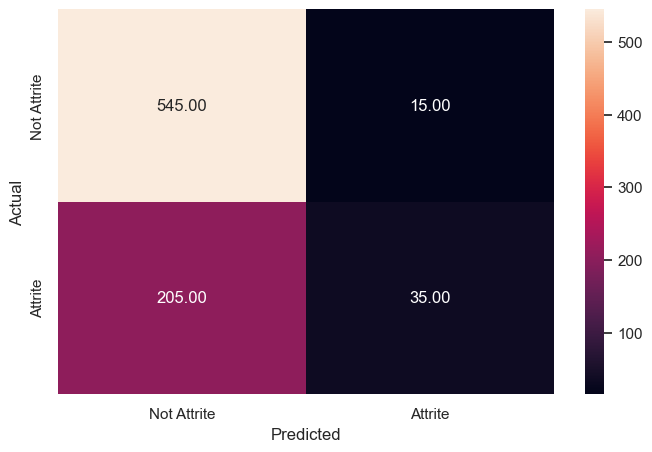

In [13]:
y_pred_train_knn = knn.predict(X_train)
metrics_score(y_train, y_pred_train_knn)

              precision    recall  f1-score   support

       False       0.73      0.95      0.83       140
        True       0.61      0.18      0.28        60

    accuracy                           0.72       200
   macro avg       0.67      0.57      0.55       200
weighted avg       0.69      0.72      0.66       200


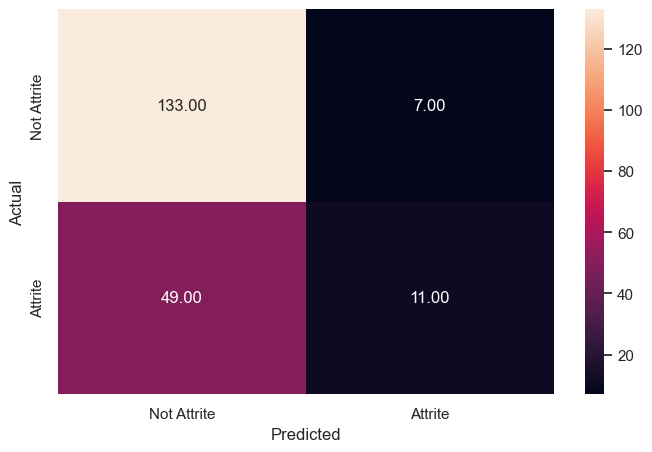

In [14]:
y_pred_test_knn = knn.predict(X_test)
metrics_score(y_test, y_pred_test_knn)

In [15]:
# GB model
params = {
    "n_estimators": 500,
    "max_depth": 4,
    "min_samples_split": 5,
    "learning_rate": 0.01,
    "loss": "squared_error",
}

gb = ensemble.GradientBoostingRegressor(**params)
gb.fit(X_train, y_train)

mse = mean_squared_error(y_test, gb.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", gb.score(X_train, y_train))
print("R2 score on test data: ", gb.score(X_test, y_test))

params = {
    "n_estimators": 500,
    "max_depth": 10,
    "min_samples_split": 5,
    "learning_rate": 0.01,
    "loss": "squared_error",
}

gb = ensemble.GradientBoostingRegressor(**params)
gb.fit(X_train, y_train)

mse = mean_squared_error(y_test, gb.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", gb.score(X_train, y_train))
print("R2 score on test data: ", gb.score(X_test, y_test))

The mean squared error (MSE) on test set: 0.1635
R2 score on training data:  0.5308242012444484
R2 score on test data:  0.2214491887687865
The mean squared error (MSE) on test set: 0.2115
R2 score on training data:  0.9901683726512466
R2 score on test data:  -0.007335923566492042


In [16]:
# Random Forest
rf = ensemble.RandomForestRegressor(max_depth=4, random_state=10)
rf.fit(X_train, y_train)

mse = mean_squared_error(y_test, rf.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", rf.score(X_train, y_train))
print("R2 score on test data: ", rf.score(X_test, y_test))

rf = ensemble.RandomForestRegressor(max_depth=10, random_state=10)
rf.fit(X_train, y_train)

mse = mean_squared_error(y_test, rf.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", rf.score(X_train, y_train))
print("R2 score on test data: ", rf.score(X_test, y_test))

The mean squared error (MSE) on test set: 0.1645
R2 score on training data:  0.3147716412639031
R2 score on test data:  0.21650081627948958
The mean squared error (MSE) on test set: 0.1602
R2 score on training data:  0.8054214865004085
R2 score on test data:  0.23736465287634823


In [17]:
# Trying CatBoost

def convert_and_return_cats(x):
    cats = []
    for col in x.columns:
        if is_numeric_dtype(x[col]):
            pass
        else:
            cats.append(col)
    cat_indices = []
    for col in cats:
        cat_indices.append(x.columns.get_loc(col))
        x[col] = x[col].astype('category')
    
    return cat_indices
df_clean = df.replace('', np.nan)
nan_values = df_clean[df_clean.isna().any(axis=1)]

X = df_clean.iloc[:,:-1]
y = df_clean['default']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1984, stratify=y)

categorical_attributes = convert_and_return_cats(X)
train_dataset = cb.Pool(X_train,y_train, cat_features=categorical_attributes)
test_dataset = cb.Pool(X_test,y_test, cat_features=categorical_attributes)

model = cb.CatBoostClassifier(loss_function='Logloss', eval_metric='Accuracy')

# grid search for hyperparameter tuning

grid = {'learning_rate': [0.03, 0.1],
        'depth': [4, 6, 10],
        'l2_leaf_reg': [1, 3, 5,],
        'iterations': [50, 100, 150]}

model.grid_search(grid,train_dataset)
model.get_params()

predictions = model.predict(X_test)
print(classification_report(y_test, predictions))


0:	learn: 0.7125000	test: 0.6500000	best: 0.6500000 (0)	total: 58.6ms	remaining: 2.87s
1:	learn: 0.7156250	test: 0.6750000	best: 0.6750000 (1)	total: 66.2ms	remaining: 1.59s
2:	learn: 0.7171875	test: 0.6687500	best: 0.6750000 (1)	total: 69ms	remaining: 1.08s
3:	learn: 0.7218750	test: 0.6562500	best: 0.6750000 (1)	total: 71.5ms	remaining: 823ms
4:	learn: 0.7171875	test: 0.6500000	best: 0.6750000 (1)	total: 73ms	remaining: 657ms
5:	learn: 0.7203125	test: 0.6562500	best: 0.6750000 (1)	total: 75ms	remaining: 550ms
6:	learn: 0.7250000	test: 0.6687500	best: 0.6750000 (1)	total: 77.2ms	remaining: 474ms
7:	learn: 0.7453125	test: 0.6750000	best: 0.6750000 (1)	total: 79.5ms	remaining: 417ms
8:	learn: 0.7421875	test: 0.6750000	best: 0.6750000 (1)	total: 83.2ms	remaining: 379ms
9:	learn: 0.7406250	test: 0.6750000	best: 0.6750000 (1)	total: 87ms	remaining: 348ms
10:	learn: 0.7421875	test: 0.6750000	best: 0.6750000 (1)	total: 90ms	remaining: 319ms
11:	learn: 0.7375000	test: 0.6750000	best: 0.6750000

Final observations and ideas for future
---------------------------------------
1. Low correlation on some features, dropping gives about the same performance.
2. Logit gives the best performance at 0.76 accuracy. CatBoost gives about the same performance. The only advantage being that we do not have to convert categorical attributes to numeric in the latter case.
3. Gradient Boosting and Random Forest perform poorly too with our fitting as we increase the depth.
3. One possible area for improvement is in the encoding of categorical features.
    3.1. Credit History - We are not sure how the difference between critical and poor is vs very good and perfect.
    3.2. Employment Duration - Can we bucket better?
    3.3. Checking and Savings Balance - These should ideally have a high predictive power when used as a numeric ordinal feature. However, I've made them binary encoded because of unknown values. If we had more training data, we could try imputing the unknowns.
4. LDA f1-score on training data suggests underfitting. Given this, we could perhaps try Target Encoder for a few of the categorical features.
5. We could also do cross-validation based improvements.